# KL robust expectations: approximation is not a bound

Finite probabilities p_i>0 and KL(q||p)<=rho. A centered log-domain exponential tilt solves the scalar KL boundary, with explicit nominal, constant-loss and saturation cases. Compare a primal SLSQP baseline, a small-radius mean-variance approximation, and an independent Bernoulli oracle. Established methods; this is not Wasserstein DRO or a calibrated confidence region.

In [1]:
import json
from pathlib import Path
r=json.loads(Path('benchmarks/results.json').read_text())
print('Predeclared gate:',r['success'])
print('Checks:',r['checks'])
print('Cases:',r['cases'])
print('SLSQP rejected:',len(r['rejected_slsqp']))
for row in r['summary']:
    print(row)

Predeclared gate: True
Checks: {'max_kl_violation': 0.0, 'max_mass_error': 5.551115123125783e-16, 'max_scaled_duality_gap': 3.677613769070831e-13, 'accepted_slsqp_fraction': 1.0, 'max_scaled_slsqp_difference': 5.793712127475385e-06, 'max_binary_oracle_error': 5.059008767460682e-13, 'rare_approximation_underestimate': 0.0026922119753416763}
Cases: 54
SLSQP rejected: 0
{'n': 3, 'cases': 18, 'slsqp_accepted': 18, 'max_gap': 3.677613769070831e-13, 'root_median_ms': 3.1147640000313004, 'slsqp_median_ms': 4.113893999999618, 'approximation_median_ms': 0.033719500038387196, 'root_peak_bytes': 4763, 'slsqp_peak_bytes': 17445}
{'n': 16, 'cases': 18, 'slsqp_accepted': 18, 'max_gap': 3.5743630277806915e-13, 'root_median_ms': 2.3151785000550262, 'slsqp_median_ms': 19.389608999972552, 'approximation_median_ms': 0.03437600003053376, 'root_peak_bytes': 5407, 'slsqp_peak_bytes': 39122}
{'n': 64, 'cases': 18, 'slsqp_accepted': 18, 'max_gap': 3.5599301284605644e-13, 'root_median_ms': 2.363429000013184, '

In [2]:
print('Two-action example (0=risky, 1=safe):')
for key,value in r['decision'].items():
    print(key,value)
assert r['decision']['mean_variance_risky_loss']<r['decision']['safe_loss']<r['decision']['exact_robust_risky_loss']

Two-action example (0=risky, 1=safe):
nominal_risky_loss 0.001
mean_variance_risky_loss 0.005469899327725402
exact_robust_risky_loss 0.008162111303067078
dual_upper 0.008162111303079533
binary_oracle 0.00816211130307954
radius 0.01
safe_loss 0.006
nominal_action 0
approximate_action 0
robust_action 1
action_labels ['risky', 'safe']
scenarios [{'scenario': 'nominal', 'true_rare_probability': 0.001, 'kl_to_nominal': 0.0, 'inside_radius': True, 'nominal_action_loss': 0.001, 'approximate_action_loss': 0.001, 'robust_action_loss': 0.006, 'best_action_loss': 0.001}, {'scenario': 'shifted', 'true_rare_probability': 0.007, 'kl_to_nominal': 0.0076394252422299575, 'inside_radius': True, 'nominal_action_loss': 0.007, 'approximate_action_loss': 0.007, 'robust_action_loss': 0.006, 'best_action_loss': 0.006}]


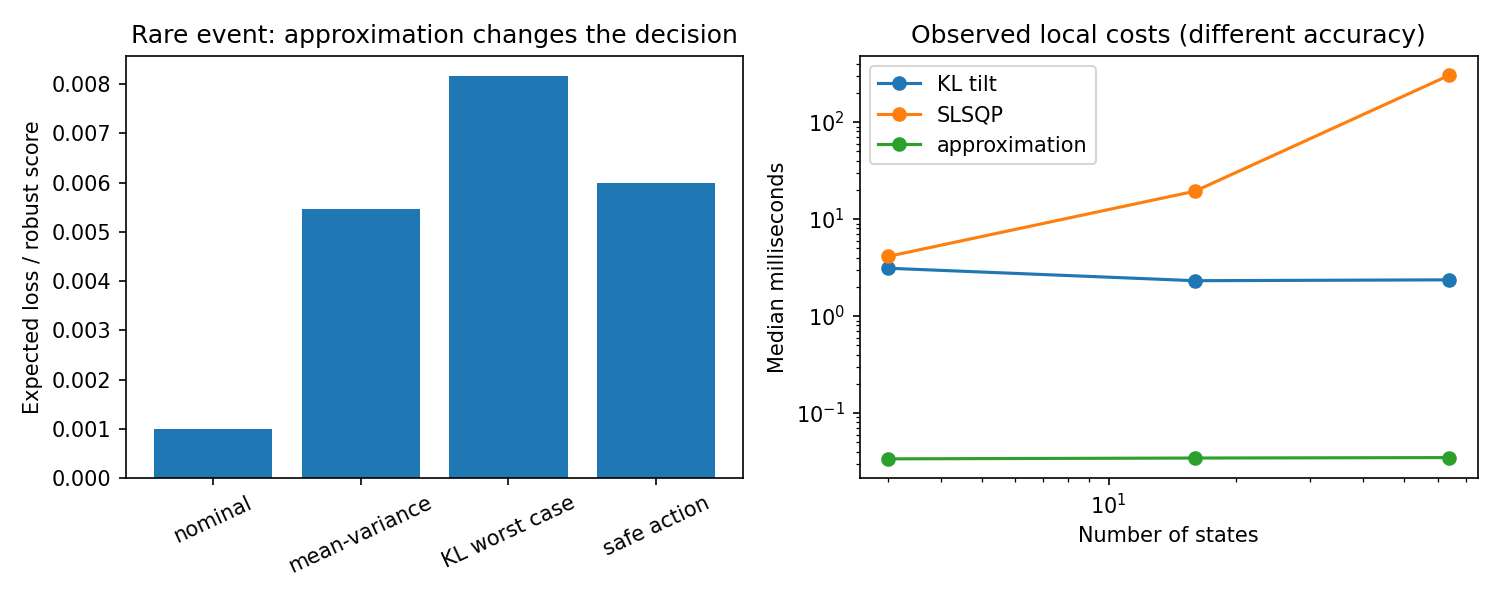

In [3]:
from IPython.display import Image,display
display(Image(filename='benchmarks/audit.png'))

In [4]:
initial=json.loads(Path('benchmarks/initial_baseline/results.json').read_text())
print('Initial baseline experiment passed?',initial['success'])
print(initial['checks'])
assert initial['success'] is False
print('Initial failed experiment retained; thresholds were not relaxed.')

Initial baseline experiment passed? False
{'max_kl_violation': 0.0, 'max_mass_error': 5.551115123125783e-16, 'max_scaled_duality_gap': 3.677613769070831e-13, 'accepted_slsqp_fraction': 0.7777777777777778, 'max_scaled_slsqp_difference': 0.0022423348831113604, 'max_binary_oracle_error': 5.059008767460682e-13, 'rare_approximation_underestimate': 0.0026922119753416763}
Initial failed experiment retained; thresholds were not relaxed.


## Conclusions and limits

The mean-variance small-radius expansion can underestimate a rare-event robust loss and change a minimax decision. It is an approximation, not a global upper bound. Robustness can cost nominal performance; both explicit scenarios are retained. Radius and support are assumed known, not estimated. The initial SLSQP configuration failed the global gate and is preserved. A stronger interior two-start configuration is compared without changing thresholds. Bounds are float64 diagnostics, not formal interval-arithmetic certificates or financial capital guarantees.